# Day 70: K-Means — sklearn + Silhouette Score

## Objective
- Cluster real-looking customer data with `KMeans(...).fit_predict(X_scaled)`
- Measure cluster quality with `silhouette_score`
- Visualize clusters on a scatter plot
- Turn clusters into a business story

> **Data note:** `dataset.csv` is a made-up lookalike of the Mall Customers dataset
> (200 customers, same column names). Replace it with the real CSV and the notebook runs unchanged.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

## Theory
- **Silhouette score** for one point = (b - a) / max(a, b)
  - `a` = average distance to points in its **own** cluster
  - `b` = average distance to points in the **nearest other** cluster
- Range is **-1 to +1**
  - near +1 = point sits well inside its cluster
  - near 0 = point is on the border between two clusters
  - negative = point may be in the wrong cluster
- `silhouette_score` = the average over all points (0.5+ suggests meaningful clusters)
- Always **scale** before K-Means, because it uses distance

In [2]:
# Load customers
df = pd.read_csv("dataset.csv")
print(df.shape)
print(df.head(3))

(200, 5)
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1  Female   56                  64                      42
1           2    Male   59                  22                      20
2           3  Female   42                  90                      80


In [3]:
# Two features make a nice 2D picture
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X_scaled = StandardScaler().fit_transform(df[features])

## Example 1: fit_predict on scaled data

In [4]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts().sort_index())

cluster
0    34
1    83
2    38
3    22
4    23
Name: count, dtype: int64


## Example 2: Silhouette score

In [5]:
# Overall score (average of every customer's silhouette)
score = silhouette_score(X_scaled, df["cluster"])
print("Silhouette score (K=5):", round(score, 3))

Silhouette score (K=5): 0.605


K = 2 -> silhouette 0.34
K = 3 -> silhouette 0.481
K = 4 -> silhouette 0.527
K = 5 -> silhouette 0.605
K = 6 -> silhouette 0.498
K = 7 -> silhouette 0.469
K = 8 -> silhouette 0.412
Best K by silhouette: 5


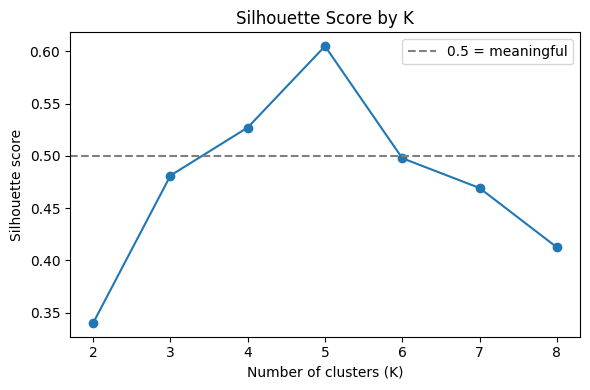

In [6]:
# Try K = 2 to 8 and compare
scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)
    print("K =", k, "-> silhouette", round(scores[k], 3))

best_k = max(scores, key=scores.get)
print("Best K by silhouette:", best_k)

plt.figure(figsize=(6, 4))
plt.plot(list(scores), list(scores.values()), marker="o")
plt.axhline(0.5, color="gray", linestyle="--", label="0.5 = meaningful")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by K")
plt.legend()
plt.tight_layout()
plt.savefig("images/silhouette_vs_k.png", dpi=150)
plt.show()

## Example 3: Which cluster is weakest?

In [7]:
# Silhouette of every single customer, then averaged per cluster
df["silhouette"] = silhouette_samples(X_scaled, df["cluster"])
print(df.groupby("cluster")["silhouette"].mean().round(3))
print("Customers with negative silhouette:", int((df["silhouette"] < 0).sum()))

cluster
0    0.614
1    0.564
2    0.636
3    0.640
4    0.655
Name: silhouette, dtype: float64
Customers with negative silhouette: 0


## Example 4: Visualize the clusters

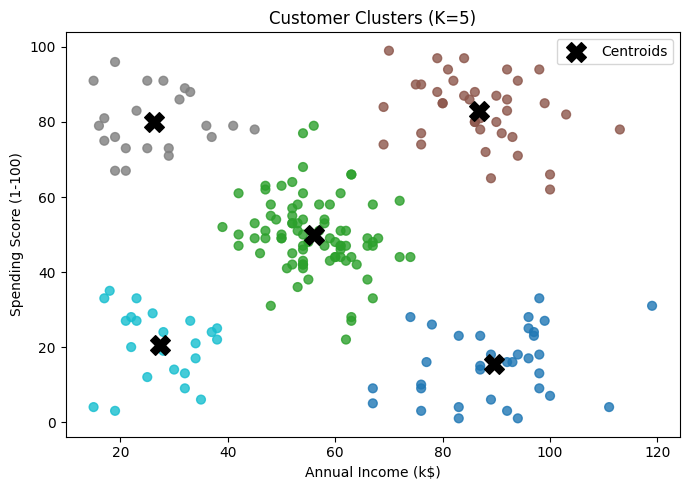

In [8]:
centers = StandardScaler().fit(df[features]).inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
plt.scatter(df[features[0]], df[features[1]], c=df["cluster"], cmap="tab10", s=40, alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Clusters (K=5)")
plt.legend()
plt.tight_layout()
plt.savefig("images/cluster_scatter.png", dpi=150)
plt.show()

## Example 5: Business interpretation

In [9]:
# Average profile of each cluster (original units)
profile = df.groupby("cluster")[features + ["Age"]].mean().round(1)
profile["customers"] = df["cluster"].value_counts().sort_index()

def name_segment(row):
    income = "High income" if row[features[0]] >= 70 else ("Low income" if row[features[0]] < 40 else "Mid income")
    spend = "high spender" if row[features[1]] >= 60 else ("low spender" if row[features[1]] < 40 else "average spender")
    return income + ", " + spend

profile["segment"] = profile.apply(name_segment, axis=1)
print(profile.sort_values(features[0]).to_string())

         Annual Income (k$)  Spending Score (1-100)   Age  customers                      segment
cluster                                                                                          
3                      26.3                    80.1  25.1         22     Low income, high spender
4                      27.4                    20.5  44.6         23      Low income, low spender
1                      56.1                    49.8  39.9         83  Mid income, average spender
2                      86.7                    83.0  34.3         38    High income, high spender
0                      89.6                    15.4  39.3         34     High income, low spender


## Example 6: Why scaling matters

In [10]:
# Same data, but income written in dollars instead of thousands
raw = df[features].copy()
raw["Annual Income (k$)"] = raw["Annual Income (k$)"] * 1000

raw_labels = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(raw)
scaled_labels = df["cluster"]

# 1.0 = identical grouping, near 0 = unrelated grouping
print("Agreement with scaled clusters:", round(adjusted_rand_score(scaled_labels, raw_labels), 3))

Agreement with scaled clusters: 0.447


## Practice Exercise
Add `Age` as a third feature (scaled). Does the silhouette score for K=5 go up or down?

In [11]:
# Your turn: 3 features
three = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X3 = StandardScaler().fit_transform(df[three])
labels3 = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(X3)
print("2 features:", round(score, 3))
print("3 features:", round(silhouette_score(X3, labels3), 3))

2 features: 0.605
3 features: 0.403


## Mini Challenge
Use `silhouette_samples` to find the 5 customers with the lowest silhouette. What do they have in common?

In [12]:
# Border customers: lowest silhouette values
border = df.sort_values("silhouette").head(5)
print(border[["CustomerID", "Annual Income (k$)", "Spending Score (1-100)", "cluster", "silhouette"]].round(2))

     CustomerID  Annual Income (k$)  Spending Score (1-100)  cluster  \
62           63                  56                      79        1   
13           14                  54                      77        1   
182         183                  62                      22        1   
109         110                  48                      31        1   
150         151                  74                      28        0   

     silhouette  
62         0.06  
13         0.06  
182        0.07  
109        0.11  
150        0.18  


## Summary
- `fit_predict` on **scaled** data gives each customer a cluster number
- Silhouette score ranges from -1 to +1, and higher means better-separated clusters
- Compare silhouette across several K values, then check against the elbow and common sense
- Plot clusters and read each cluster's average profile to find the business meaning
- Scaling changes the answer, so never skip it